# Customer Behaviour Fraud Risk Prediction Model

## Project Overview

This notebook analyses transaction behaviour to investigate whether a customer's historical activity can provide useful information for assessing potential fraud risk.

The analysis progresses from exploratory analysis and behavioural feature engineering to supervised models, anomaly detection, model comparison and Explainable AI.

**Important:** The models are used for risk ranking and investigation support, not as an automatic final fraud decision.

## 1. Load and Understand the Data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

train = pd.read_csv("/content/train (3).csv")

print("Training shape:", train.shape)
train.head()

Training shape: (182125, 10)
Test shape: (45531, 9)


,transaction_id,user_id,timestamp,amount,merchant_category,country,device_id,channel,hours_since_prev_txn,label
0,243747,3399,2804395,28.632151,0,11,22279,1,232259.0,0
1,88525,317,1022027,51.946133,14,14,9154,1,211366.0,0
2,214788,2095,2471000,13.033808,13,23,21154,0,33513.0,0
3,63117,2156,728428,26.546503,18,20,50757,1,4380.0,0
4,112859,4687,1304407,6.759898,2,8,12561,0,40655.0,0


In [ ]:
print("Columns:")
print(train.columns.tolist())

print("\nData types and non-null counts:")
train.info()

Columns:
['transaction_id', 'user_id', 'timestamp', 'amount', 'merchant_category', 'country', 'device_id', 'channel', 'hours_since_prev_txn', 'label']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 182125 entries, 0 to 182124
Data columns (total 10 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   transaction_id        182125 non-null  int64  
 1   user_id               182125 non-null  int64  
 2   timestamp             182125 non-null  int64  
 3   amount                182125 non-null  float64
 4   merchant_category     182125 non-null  int64  
 5   country               182125 non-null  int64  
 6   device_id             182125 non-null  int64  
 7   channel               182125 non-null  int64  
 8   hours_since_prev_txn  182125 non-null  float64
 9   label                 182125 non-null  int64  
dtypes: float64(2), int64(8)
memory usage: 13.9 MB


In [ ]:
train.describe(include="all").T

,count,mean,std,min,25%,50%,75%,max
transaction_id,182125.0,1.248637e+05,72205.218553,0.000000,62276.000000,1.247810e+05,1.873690e+05,2.499990e+05
user_id,182125.0,2.500040e+03,1444.185807,0.000000,1249.000000,2.504000e+03,3.747000e+03,4.999000e+03
timestamp,182125.0,1.439129e+06,830477.123745,6.000000,718402.000000,1.440213e+06,2.159064e+06,2.874525e+06
amount,182125.0,2.729534e+01,24.978242,0.364086,11.930504,2.006668e+01,3.399739e+01,6.398981e+02
merchant_category,182125.0,9.447742e+00,5.785112,0.000000,4.000000,9.000000e+00,1.400000e+01,1.900000e+01
country,182125.0,1.439405e+01,8.634999,0.000000,7.000000,1.400000e+01,2.200000e+01,2.900000e+01
device_id,182125.0,4.003250e+04,23081.822548,1.000000,19880.000000,4.013900e+04,5.996400e+04,7.999700e+04
channel,182125.0,2.993713e-01,0.457984,0.000000,0.000000,0.000000e+00,1.000000e+00,1.000000e+00
hours_since_prev_txn,182125.0,5.525685e+04,56550.922597,0.000000,15138.000000,3.779300e+04,7.696500e+04,8.697940e+05
label,182125.0,1.641730e-02,0.127074,0.000000,0.000000,0.000000e+00,0.000000e+00,1.000000e+00


## 2. Data Quality and Fraud Distribution

In [ ]:
missing_values = train.isnull().sum()

print("Missing values:")
print(missing_values[missing_values > 0])

print("\nTotal missing values:", missing_values.sum())

Missing values:
transaction_id          0
user_id                 0
timestamp               0
amount                  0
merchant_category       0
country                 0
device_id               0
channel                 0
hours_since_prev_txn    0
label                   0
dtype: int64

Missing-value percentage:
transaction_id          0.0
user_id                 0.0
timestamp               0.0
amount                  0.0
merchant_category       0.0
country                 0.0
device_id               0.0
channel                 0.0
hours_since_prev_txn    0.0
label                   0.0
dtype: float64


In [ ]:
label_counts = train["label"].value_counts()

print("Transaction counts:")
print(label_counts)

print("\nFraud rate:")
print(train["label"].mean())

Counts:
label
0    179135
1      2990
Name: count, dtype: int64

Percentage distribution:
label
0    98.36
1     1.64
Name: proportion, dtype: float64


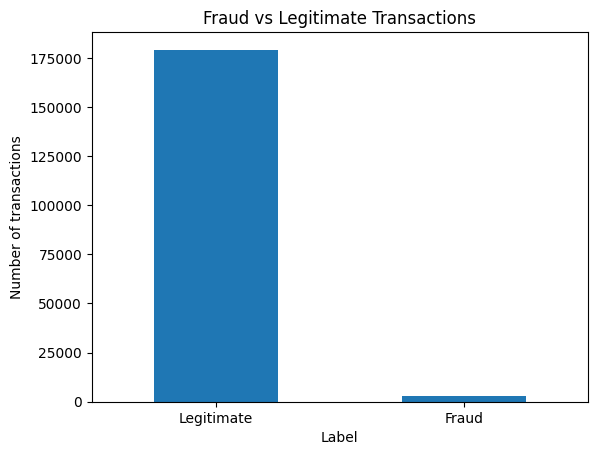

In [ ]:
label_counts.plot(
    kind="bar",
    xlabel="Label",
    ylabel="Number of transactions",
    title="Legitimate vs Fraudulent Transactions"
)
plt.tight_layout()
plt.show()

### Class imbalance

Fraud is much less common than legitimate activity. This imbalance is important when evaluating fraud-risk models, because accuracy alone can give a misleading impression of performance.

## 3. Initial Transaction Behaviour

In [ ]:
print("Transaction amount by class:")
display(train.groupby("label")["amount"].describe())

print("\nAverage transaction amount by class:")
print(train.groupby("label")["amount"].mean())

Average transaction amount by class:
label
0    27.257979
1    29.533426
Name: amount, dtype: float64

Median transaction amount by class:
label
0    20.061662
1    20.414823
Name: amount, dtype: float64


In [ ]:
transactions_per_user = train.groupby("user_id").size()

print(transactions_per_user.describe())

transactions_per_user.hist(bins=50)
plt.xlabel("Number of transactions per customer")
plt.ylabel("Number of customers")
plt.title("Customer Transaction Frequency")
plt.tight_layout()
plt.show()

,0
count,5000.000000
mean,36.425000
std,5.956431
min,18.000000
25%,32.000000
50%,36.000000
75%,40.000000
max,60.000000


In [ ]:
print("Timestamp range:")
print(train["timestamp"].min(), "to", train["timestamp"].max())

print("\nUnique devices:", train["device_id"].nunique())
print("Unique countries:", train["country"].nunique())
print("Unique merchant categories:", train["merchant_category"].nunique())
print("Unique channels:", train["channel"].nunique())

Timestamp range:
6
2874525

Unique devices: 8743
Unique countries: 30
Unique merchant categories: 20
Unique channels: 2


## 4. Customer Behaviour Feature Engineering

In [ ]:
# Sort transactions chronologically within each customer.
df = train.copy()
df = df.sort_values(["user_id", "timestamp"]).reset_index(drop=True)

df[["user_id", "timestamp", "amount", "label"]].head(10)

,user_id,timestamp,amount,label
0,0,10592,18.389259,0
1,0,217145,14.389810,0
2,0,328344,12.909633,0
3,0,556926,17.711028,0
4,0,833227,37.555375,0
5,0,953758,16.770519,0
6,0,995719,9.665956,0
7,0,1127575,14.192436,0
8,0,1130376,36.232138,0
9,0,1271615,23.210115,0


In [ ]:
# Previous transaction amount and historical average spending.
df["previous_amount"] = (
    df.groupby("user_id")["amount"].shift(1)
)

df["previous_avg_amount"] = (
    df.groupby("user_id")["amount"]
      .transform(lambda x: x.shift(1).expanding().mean())
)

# Current amount relative to the customer's historical average.
df["amount_to_previous_avg"] = (
    df["amount"] / df["previous_avg_amount"]
)

# Number of transactions observed before the current transaction.
df["previous_transaction_count"] = (
    df.groupby("user_id").cumcount()
)

In [ ]:
# Whether the current device or country has been seen before for this customer.
def seen_before(series):
    seen = set()
    result = []

    for value in series:
        result.append(int(value in seen))
        seen.add(value)

    return pd.Series(result, index=series.index)

df["device_seen_before"] = (
    df.groupby("user_id")["device_id"]
      .transform(seen_before)
)

df["country_seen_before"] = (
    df.groupby("user_id")["country"]
      .transform(seen_before)
)

df["merchant_category_seen_before"] = (
    df.groupby("user_id")["merchant_category"]
      .transform(seen_before)
)

df["previous_device"] = (
    df.groupby("user_id")["device_id"].shift(1)
)

df["device_changed"] = (
    df["device_id"] != df["previous_device"]
).astype(int)

df["previous_country"] = (
    df.groupby("user_id")["country"].shift(1)
)

df["country_changed"] = (
    df["country"] != df["previous_country"]
).astype(int)

In [ ]:
# Time since the customer's previous transaction.
df["time_since_previous"] = (
    df.groupby("user_id")["timestamp"].diff()
)

# Customer's historical average time gap.
df["previous_avg_time_gap"] = (
    df.groupby("user_id")["time_since_previous"]
      .transform(lambda x: x.shift(1).expanding().mean())
)

# Current time gap relative to the customer's historical average.
df["time_gap_ratio"] = (
    df["time_since_previous"] / df["previous_avg_time_gap"]
)

short_gap_threshold = df["time_since_previous"].quantile(0.10)

df["unusually_short_gap"] = (
    df["time_since_previous"] <= short_gap_threshold
).astype(int)

In [ ]:
behaviour_features = [
    "previous_avg_amount",
    "amount_to_previous_avg",
    "previous_transaction_count",
    "device_seen_before",
    "country_seen_before",
    "time_since_previous",
    "previous_avg_time_gap",
    "time_gap_ratio",
    "unusually_short_gap"
]

print("Behavioural features:")
print(behaviour_features)

## 5. Prepare a Chronological Train/Validation Split

In [ ]:
# The first transaction for a customer does not have historical behaviour,
# so rows requiring previous behaviour are excluded.
df_model = df.dropna(
    subset=[
        "previous_avg_amount",
        "amount_to_previous_avg",
        "time_since_previous",
        "previous_avg_time_gap",
        "time_gap_ratio"
    ]
).copy()

df_model = df_model.sort_values("timestamp").reset_index(drop=True)

split_point = int(len(df_model) * 0.80)

train_model = df_model.iloc[:split_point].copy()
valid_model = df_model.iloc[split_point:].copy()

print("Training rows:", len(train_model))
print("Validation rows:", len(valid_model))

print("\nTraining time range:",
      train_model["timestamp"].min(),
      "to",
      train_model["timestamp"].max())

print("Validation time range:",
      valid_model["timestamp"].min(),
      "to",
      valid_model["timestamp"].max())

Training rows: 137700
Validation rows: 34425

Training time range:
7259 to 2333241

Validation time range:
2333245 to 2874525


## 6. Baseline: Transaction Information Only

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score

transaction_features = [
    "amount",
    "merchant_category",
    "country",
    "device_id",
    "channel",
    "hours_since_prev_txn"
]

X_train_transaction = train_model[transaction_features]
y_train = train_model["label"]

X_valid_transaction = valid_model[transaction_features]
y_valid = valid_model["label"]

baseline_model = DecisionTreeClassifier(
    max_depth=6,
    random_state=42,
    class_weight="balanced"
)

baseline_model.fit(X_train_transaction, y_train)

baseline_probabilities = baseline_model.predict_proba(
    X_valid_transaction
)[:, 1]

baseline_auc = roc_auc_score(
    y_valid,
    baseline_probabilities
)

print("Transaction-only ROC-AUC:", round(baseline_auc, 4))

Baseline ROC-AUC: 0.5184


## 7. Add Customer Behaviour

In [ ]:
all_features = transaction_features + behaviour_features

X_train_behaviour = train_model[all_features]
X_valid_behaviour = valid_model[all_features]

behaviour_model = DecisionTreeClassifier(
    max_depth=6,
    random_state=42,
    class_weight="balanced"
)

behaviour_model.fit(
    X_train_behaviour,
    y_train
)

behaviour_probabilities = behaviour_model.predict_proba(
    X_valid_behaviour
)[:, 1]

behaviour_auc = roc_auc_score(
    y_valid,
    behaviour_probabilities
)

print("Behaviour-enhanced ROC-AUC:", round(behaviour_auc, 4))

Behaviour-enhanced ROC-AUC: 0.5185


In [ ]:
feature_importance = pd.DataFrame({
    "feature": all_features,
    "importance": behaviour_model.feature_importances_
}).sort_values("importance", ascending=False)

print(feature_importance.to_string(index=False))

                   feature  importance
    amount_to_previous_avg    0.293861
       previous_avg_amount    0.156539
                 device_id    0.118957
                    amount    0.117049
     previous_avg_time_gap    0.095637
       time_since_previous    0.064840
            time_gap_ratio    0.048945
                   country    0.048410
      hours_since_prev_txn    0.036816
         merchant_category    0.018529
previous_transaction_count    0.000416
                   channel    0.000000
        device_seen_before    0.000000
       country_seen_before    0.000000
       unusually_short_gap    0.000000


In [ ]:
df_analysis = df_model.copy()

df_analysis["amount_ratio_group"] = pd.cut(
    df_analysis["amount_to_previous_avg"],
    bins=[0, 0.5, 1, 2, 3, np.inf],
    labels=["<0.5x", "0.5–1x", "1–2x", "2–3x", ">3x"]
)

ratio_analysis = (
    df_analysis
    .groupby("amount_ratio_group", observed=False)["label"]
    .agg(
        transactions="count",
        fraud_count="sum",
        fraud_rate="mean"
    )
)

ratio_analysis["fraud_rate_percent"] = (
    ratio_analysis["fraud_rate"] * 100
)

print("Fraud rate by transaction amount relative to customer history:")
print(ratio_analysis)

Fraud rate by transaction amount relative to customer history:
                    transactions  fraud_count  fraud_rate  fraud_rate_percent
amount_ratio_group                                                           
<0.5x                      22624          346    0.015293            1.529349
0.5–1x                     77929         1242    0.015938            1.593758
1–2x                       61230          936    0.015287            1.528662
2–3x                        8643          237    0.027421            2.742103
>3x                         1699           78    0.045909            4.590936


## 8. Improved Behavioural Features

In [ ]:
df_features = df_model.copy()

# Spending deviation from the customer's historical average.
df_features["amount_deviation"] = (
    df_features["amount"]
    - df_features["previous_avg_amount"]
)

df_features["abs_amount_deviation"] = (
    df_features["amount_deviation"].abs()
)

# Timing deviation from the customer's historical average.
df_features["time_gap_deviation"] = (
    df_features["time_since_previous"]
    - df_features["previous_avg_time_gap"]
)

df_features["abs_time_gap_deviation"] = (
    df_features["time_gap_deviation"].abs()
)

df_features["time_gap_ratio"] = (
    df_features["time_since_previous"]
    / df_features["previous_avg_time_gap"]
).replace([np.inf, -np.inf], np.nan)

new_features = [
    "amount_deviation",
    "abs_amount_deviation",
    "time_gap_deviation",
    "abs_time_gap_deviation",
    "time_gap_ratio"
]

print("New behavioural features:")
print(new_features)

In [ ]:
all_improved_features = list(dict.fromkeys(
    transaction_features
    + behaviour_features
    + new_features
))

train_c = df_features[
    df_features["timestamp"] <= 2333241
].copy()

valid_c = df_features[
    df_features["timestamp"] >= 2333245
].copy()

X_train_c = train_c[all_improved_features]
y_train_c = train_c["label"]

X_valid_c = valid_c[all_improved_features]
y_valid_c = valid_c["label"]

model_c = DecisionTreeClassifier(
    max_depth=6,
    random_state=42,
    class_weight="balanced"
)

model_c.fit(X_train_c, y_train_c)

model_c_probabilities = model_c.predict_proba(
    X_valid_c
)[:, 1]

model_c_auc = roc_auc_score(
    y_valid_c,
    model_c_probabilities
)

print("Improved behaviour ROC-AUC:", round(model_c_auc, 4))

Model C ROC-AUC: 0.5229


## 9. Model Comparison: Random Forest and Calibration

In [ ]:
from sklearn.ensemble import RandomForestClassifier

model_d = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model_d.fit(X_train_c, y_train_c)

model_d_probabilities = model_d.predict_proba(
    X_valid_c
)[:, 1]

model_d_auc = roc_auc_score(
    y_valid_c,
    model_d_probabilities
)

print("Random Forest ROC-AUC:", round(model_d_auc, 4))

Random Forest ROC-AUC: 0.4927


In [ ]:
from sklearn.calibration import CalibratedClassifierCV

calibrated_model = CalibratedClassifierCV(
    model_c,
    method="sigmoid",
    cv=3
)

calibrated_model.fit(
    X_train_c,
    y_train_c
)

calibrated_probabilities = calibrated_model.predict_proba(
    X_valid_c
)[:, 1]

calibrated_auc = roc_auc_score(
    y_valid_c,
    calibrated_probabilities
)

print("Original Model C ROC-AUC:", round(model_c_auc, 4))
print("Calibrated Model C ROC-AUC:", round(calibrated_auc, 4))

Original Model C ROC-AUC: 0.5229
Calibrated Model C ROC-AUC: 0.5517

Calibrated probability summary:
count    34425.000000
mean         0.016501
std          0.000620
min          0.012234
25%          0.016300
50%          0.016523
75%          0.016676
max          0.020432
dtype: float64


In [ ]:
calibrated_check = pd.DataFrame({
    "probability": calibrated_probabilities,
    "actual_label": y_valid_c.values
})

calibrated_check["risk_group"] = pd.qcut(
    calibrated_check["probability"],
    q=5,
    labels=["Very Low", "Low", "Medium", "High", "Very High"],
    duplicates="drop"
)

calibrated_risk = (
    calibrated_check
    .groupby("risk_group", observed=False)["actual_label"]
    .agg(
        transactions="count",
        fraud_count="sum",
        fraud_rate="mean"
    )
)

calibrated_risk["fraud_rate_percent"] = (
    calibrated_risk["fraud_rate"] * 100
)

print("Fraud rate by calibrated risk group:")
print(calibrated_risk)

Fraud rate by calibrated risk group:
            transactions  fraud_count  fraud_rate  fraud_rate_percent
risk_group                                                           
Very Low            6886           90    0.013070            1.307000
Low                 7090          105    0.014810            1.480959
Medium              8707          128    0.014701            1.470082
High                4996           87    0.017414            1.741393
Very High           6746          141    0.020901            2.090127


## 10. Gradient Boosting

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier

df_improved = df_features.copy()

df_improved["log_time_gap_ratio"] = np.log1p(
    df_improved["time_gap_ratio"]
)

df_improved["log_abs_amount_deviation"] = np.log1p(
    df_improved["abs_amount_deviation"]
)

df_improved["log_abs_time_gap_deviation"] = np.log1p(
    df_improved["abs_time_gap_deviation"]
)

df_improved = df_improved.replace(
    [np.inf, -np.inf],
    np.nan
)

improved_features = [
    "amount_to_previous_avg",
    "amount_deviation",
    "abs_amount_deviation",
    "log_abs_amount_deviation",
    "time_gap_ratio",
    "log_time_gap_ratio",
    "time_gap_deviation",
    "abs_time_gap_deviation",
    "log_abs_time_gap_deviation",
    "previous_avg_amount",
    "previous_transaction_count",
    "device_seen_before",
    "country_seen_before"
]

final_features = list(dict.fromkeys(
    transaction_features + improved_features
))

df_final = df_improved.dropna(
    subset=final_features + ["label"]
).copy()

train_final = df_final[
    df_final["timestamp"] <= 2333241
].copy()

valid_final = df_final[
    df_final["timestamp"] >= 2333245
].copy()

X_train_final = train_final[final_features]
y_train_final = train_final["label"]

X_valid_final = valid_final[final_features]
y_valid_final = valid_final["label"]

gradient_model = HistGradientBoostingClassifier(
    max_iter=200,
    learning_rate=0.05,
    max_leaf_nodes=15,
    min_samples_leaf=30,
    random_state=42
)

gradient_model.fit(
    X_train_final,
    y_train_final
)

gradient_probabilities = gradient_model.predict_proba(
    X_valid_final
)[:, 1]

gradient_auc = roc_auc_score(
    y_valid_final,
    gradient_probabilities
)

print("Gradient Boosting ROC-AUC:", round(gradient_auc, 4))

Gradient Boosting ROC-AUC: 0.5332


## 11. Isolation Forest: Unusual Behaviour

In [ ]:
from sklearn.ensemble import IsolationForest

X_train_if = X_train_final.copy()
X_valid_if = X_valid_final.copy()

isolation_model = IsolationForest(
    n_estimators=200,
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

isolation_model.fit(X_train_if)

# Higher values are made to represent greater anomaly/risk.
anomaly_scores = -isolation_model.decision_function(
    X_valid_if
)

isolation_auc = roc_auc_score(
    y_valid_final,
    anomaly_scores
)

print("Isolation Forest ROC-AUC:", round(isolation_auc, 4))

Isolation Forest ROC-AUC: 0.5263


In [ ]:
if_check = pd.DataFrame({
    "anomaly_score": anomaly_scores,
    "actual_fraud": y_valid_final.values
})

if_check["risk_group"] = pd.qcut(
    if_check["anomaly_score"],
    q=5,
    labels=["Very Low", "Low", "Medium", "High", "Very High"],
    duplicates="drop"
)

if_risk = (
    if_check
    .groupby("risk_group", observed=False)["actual_fraud"]
    .agg(
        transactions="count",
        fraud_count="sum",
        fraud_rate="mean"
    )
)

if_risk["fraud_rate_percent"] = (
    if_risk["fraud_rate"] * 100
)

print("Fraud rate by Isolation Forest anomaly group:")
print(if_risk)

Fraud rate by Isolation Forest anomaly group:
            transactions  fraud_count  fraud_rate  fraud_rate_percent
risk_group                                                           
Very Low            6885          109    0.015832            1.583152
Low                 6885          105    0.015251            1.525054
Medium              6885           89    0.012927            1.292665
High                6885          109    0.015832            1.583152
Very High           6885          139    0.020189            2.018882


## 12. Combined Model: Add the Anomaly Signal

In [ ]:
# The anomaly score becomes an additional feature for the supervised model.
train_anomaly_scores = -isolation_model.decision_function(
    X_train_if
)

valid_anomaly_scores = anomaly_scores

X_train_combined = X_train_final.copy()
X_valid_combined = X_valid_final.copy()

X_train_combined["anomaly_score"] = train_anomaly_scores
X_valid_combined["anomaly_score"] = valid_anomaly_scores

In [ ]:
combined_model = HistGradientBoostingClassifier(
    max_iter=200,
    learning_rate=0.05,
    max_leaf_nodes=15,
    min_samples_leaf=30,
    random_state=42
)

combined_model.fit(
    X_train_combined,
    y_train_final
)

combined_probabilities = combined_model.predict_proba(
    X_valid_combined
)[:, 1]

combined_auc = roc_auc_score(
    y_valid_final,
    combined_probabilities
)

print("Combined Gradient Boosting ROC-AUC:",
      round(combined_auc, 4))

Combined Gradient Boosting ROC-AUC: 0.5367


In [ ]:
combined_check = pd.DataFrame({
    "risk_probability": combined_probabilities,
    "actual_fraud": y_valid_final.values
})

combined_check["risk_group"] = pd.qcut(
    combined_check["risk_probability"].rank(method="first"),
    q=5,
    labels=["Very Low", "Low", "Medium", "High", "Very High"]
)

combined_risk = (
    combined_check
    .groupby("risk_group", observed=False)["actual_fraud"]
    .agg(
        transactions="count",
        fraud_count="sum",
        fraud_rate="mean"
    )
)

combined_risk["fraud_rate_percent"] = (
    combined_risk["fraud_rate"] * 100
)

print("Fraud rate by combined-model risk group:")
print(combined_risk)

Fraud rate by combined-model risk group:
            transactions  fraud_count  fraud_rate  fraud_rate_percent
risk_group                                                           
Very Low            6885          100    0.014524            1.452433
Low                 6885          103    0.014960            1.496006
Medium              6885          105    0.015251            1.525054
High                6885          109    0.015832            1.583152
Very High           6885          134    0.019463            1.946260


## 13. CatBoost: Final Categorical Model

In [ ]:
from catboost import CatBoostClassifier

X_train_cat = X_train_combined.copy()
X_valid_cat = X_valid_combined.copy()

categorical_features = [
    "device_id",
    "country",
    "merchant_category",
    "channel"
]

for col in categorical_features:
    X_train_cat[col] = X_train_cat[col].astype(str)
    X_valid_cat[col] = X_valid_cat[col].astype(str)

cat_model = CatBoostClassifier(
    iterations=300,
    depth=6,
    learning_rate=0.05,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    verbose=False,
    thread_count=-1
)

cat_model.fit(
    X_train_cat,
    y_train_final,
    cat_features=categorical_features
)

cat_probabilities = cat_model.predict_proba(
    X_valid_cat
)[:, 1]

cat_auc = roc_auc_score(
    y_valid_final,
    cat_probabilities
)

print("CatBoost ROC-AUC:", round(cat_auc, 4))

CatBoost ROC-AUC: 0.544


## 14. Explainable AI

In [ ]:
# Global CatBoost feature importance.
feature_importance = pd.DataFrame({
    "feature": X_train_cat.columns,
    "importance": cat_model.get_feature_importance()
}).sort_values("importance", ascending=False)

print(feature_importance.to_string(index=False))

CatBoost Feature Importance:
                   feature  importance
                 device_id   11.423268
    amount_to_previous_avg   10.880712
       previous_avg_amount    7.406843
                    amount    7.402227
             anomaly_score    6.772337
previous_transaction_count    6.534039
          amount_deviation    6.469856
      abs_amount_deviation    5.684492
      hours_since_prev_txn    5.286281
    abs_time_gap_deviation    4.529204
            time_gap_ratio    3.921020
  log_abs_amount_deviation    3.681908
log_abs_time_gap_deviation    3.650432
         merchant_category    3.637601
        log_time_gap_ratio    3.292531
                   country    3.267914
        time_gap_deviation    2.956247
       country_seen_before    1.988449
                   channel    0.789504
        device_seen_before    0.425136


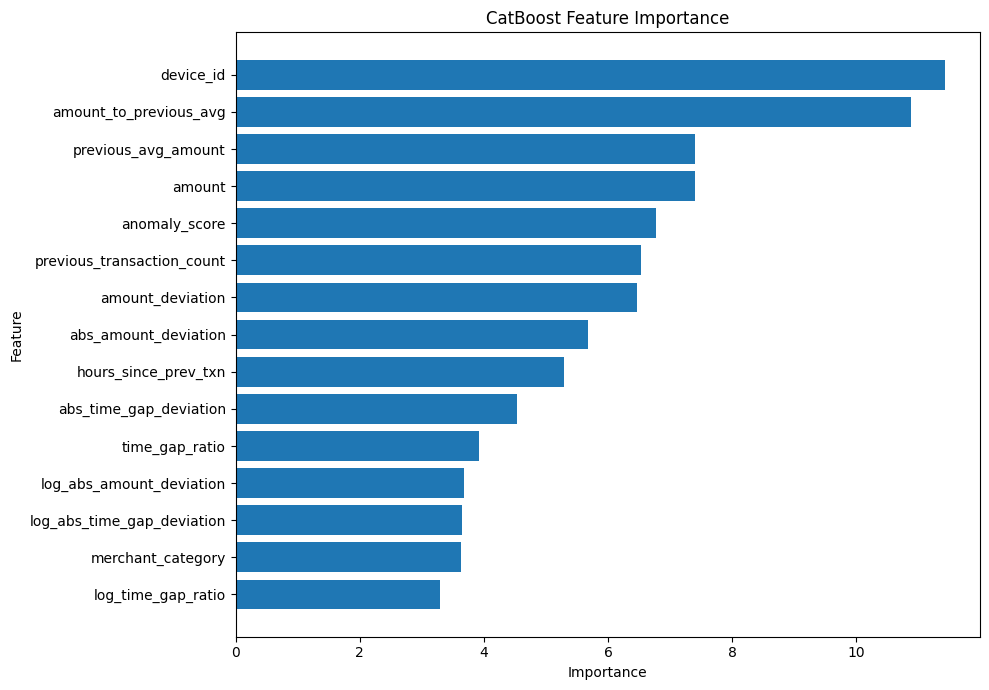

In [ ]:
plt.figure(figsize=(10, 7))

top_features = feature_importance.head(15).sort_values("importance")

plt.barh(
    top_features["feature"],
    top_features["importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("CatBoost Feature Importance")
plt.tight_layout()
plt.show()

In [ ]:
import shap

X_cat_shap = X_valid_cat.sample(
    min(3000, len(X_valid_cat)),
    random_state=42
)

cat_explainer = shap.TreeExplainer(cat_model)

cat_shap_values = cat_explainer.shap_values(
    X_cat_shap
)

print("Transactions explained:", len(X_cat_shap))

SHAP analysis completed.
Transactions explained: 3000
Features explained: 20


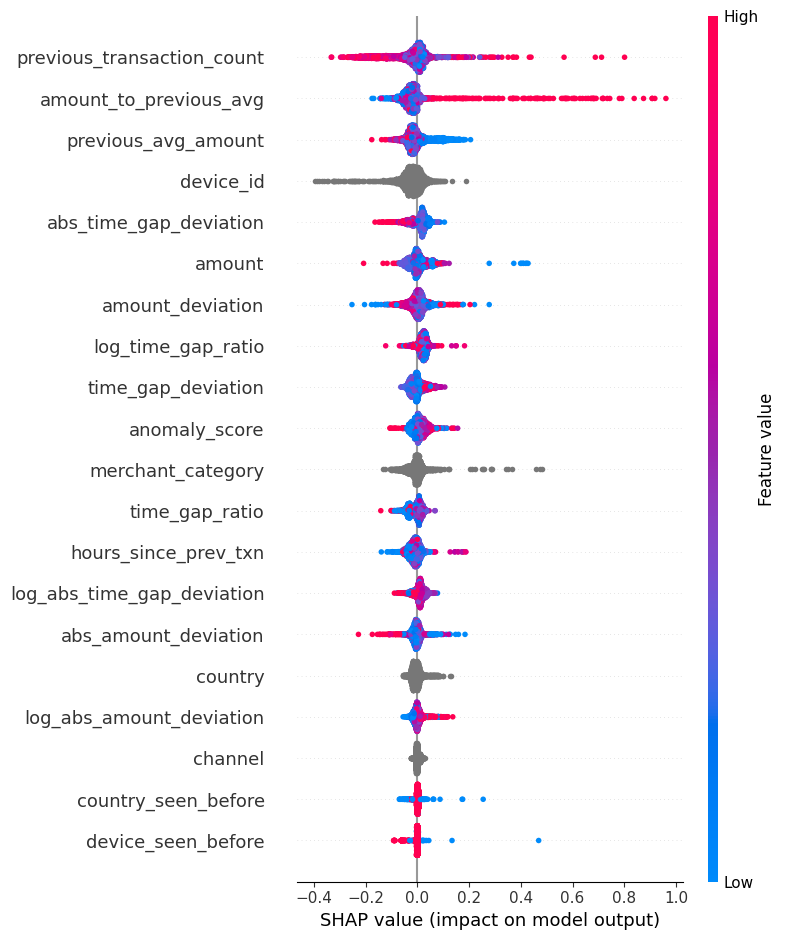

In [ ]:
shap.summary_plot(
    cat_shap_values,
    X_cat_shap,
    max_display=20
)

In [ ]:
# Explain the highest-risk validation transaction.
cat_risk = X_valid_cat.copy()
cat_risk["predicted_risk"] = cat_probabilities

highest_risk_index = (
    cat_risk["predicted_risk"].idxmax()
)

highest_risk_transaction = X_valid_cat.loc[
    highest_risk_index
]

single_cat_shap = cat_explainer(
    highest_risk_transaction.to_frame().T
)

position = list(X_valid_cat.index).index(
    highest_risk_index
)

print("Highest-risk transaction:")
print(highest_risk_transaction)

print("\nPredicted fraud probability:",
      round(cat_probabilities[position], 4))

Highest-risk transaction:
amount                          89.795548
merchant_category                       2
country                                14
device_id                           32953
channel                                 0
hours_since_prev_txn              58730.0
amount_to_previous_avg           3.950206
amount_deviation                67.063684
abs_amount_deviation            67.063684
log_abs_amount_deviation         4.220444
time_gap_ratio                   1.126337
log_time_gap_ratio               0.754401
time_gap_deviation            6587.522727
abs_time_gap_deviation        6587.522727
log_abs_time_gap_deviation       8.793084
previous_avg_amount             22.731864
previous_transaction_count             45
device_seen_before                      1
country_seen_before                     0
anomaly_score                    0.130223
Name: 152036, dtype: object

Predicted fraud probability:
0.2359


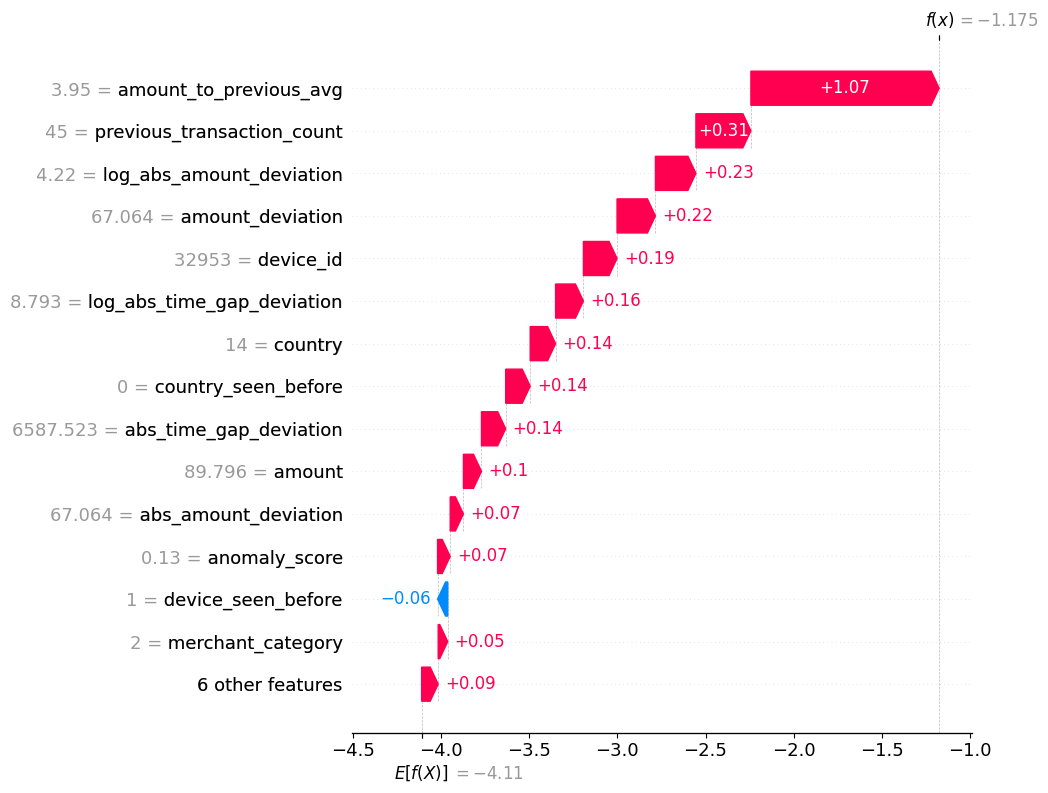

In [ ]:
shap.plots.waterfall(
    single_cat_shap[0],
    max_display=15
)

## 15. Final Model Comparison

In [ ]:
results = pd.DataFrame({
    "Model": [
        "Transaction only",
        "Original behaviour",
        "Improved behaviour",
        "Random Forest",
        "Gradient Boosting",
        "Isolation Forest",
        "Gradient Boosting + anomaly",
        "Calibrated behaviour model",
        "CatBoost"
    ],
    "ROC-AUC": [
        baseline_auc,
        behaviour_auc,
        model_c_auc,
        model_d_auc,
        gradient_auc,
        isolation_auc,
        combined_auc,
        calibrated_auc,
        cat_auc
    ]
}).sort_values("ROC-AUC", ascending=False)

print(results.to_string(index=False))

## 16. Interpretation and Conclusion

The analysis suggests that customer-relative behaviour provides useful context for fraud-risk assessment.

The strongest behavioural signal came from comparing a transaction with the customer's historical activity, particularly transaction amount relative to previous spending.

Isolation Forest added a separate view of unusual behaviour. Its anomaly score was then supplied to the combined supervised model as an additional feature rather than being directly averaged with the fraud probability.

CatBoost provided a further comparison while handling categorical variables directly.

The final results should be interpreted as **risk ranking and investigation support**, not as proof that an individual transaction is fraudulent.

### Key limitation

The predictive performance is modest. This is important to acknowledge: the project demonstrates the modelling approach and the value of behavioural analysis, but the results do not justify fully automated fraud decisions in a real-world setting.

## 17. Export Models for the Streamlit Dashboard

The export cell below saves the trained models and the feature metadata needed by the separate Streamlit application.

Run it only after the modelling and CatBoost sections have completed.

In [ ]:
import joblib
import os

joblib.dump(
    cat_model,
    "/content/catboost_fraud_model.pkl"
)

joblib.dump(
    isolation_model,
    "/content/isolation_forest_model.pkl"
)

model_metadata = {
    "final_features": list(X_train_combined.columns),
    "categorical_features": list(categorical_features)
}

joblib.dump(
    model_metadata,
    "/content/fraud_model_metadata.pkl"
)

demo = X_valid_cat.copy()
demo["predicted_probability"] = cat_probabilities
demo["actual_label"] = y_valid_final.values
demo["validation_index"] = demo.index

demo.to_csv(
    "/content/fraud_validation_demo.csv",
    index=False
)

print("Export complete.")
for file in [
    "/content/catboost_fraud_model.pkl",
    "/content/isolation_forest_model.pkl",
    "/content/fraud_model_metadata.pkl",
    "/content/fraud_validation_demo.csv"
]:
    print(f"{os.path.basename(file)}: {os.path.getsize(file):,} bytes")